In [14]:
import os
from pathlib import Path
from dotenv import load_dotenv
from openai import OpenAI

PROJECT_DIR = Path(
    "/home/abi/vison-model/Vision-Based Product Attribution and BOM Mapping"
)

load_dotenv(PROJECT_DIR / ".env", override=False)

api_key = os.getenv("OPENAI_API_KEY")

if not api_key:
    raise ValueError(
        "OPENAI_API_KEY not found in the project's .env file. "
        "Please check that the variable exists."
    )

client = OpenAI(api_key=api_key)

print("OpenAI client initialized successfully!")

OpenAI client initialized successfully!


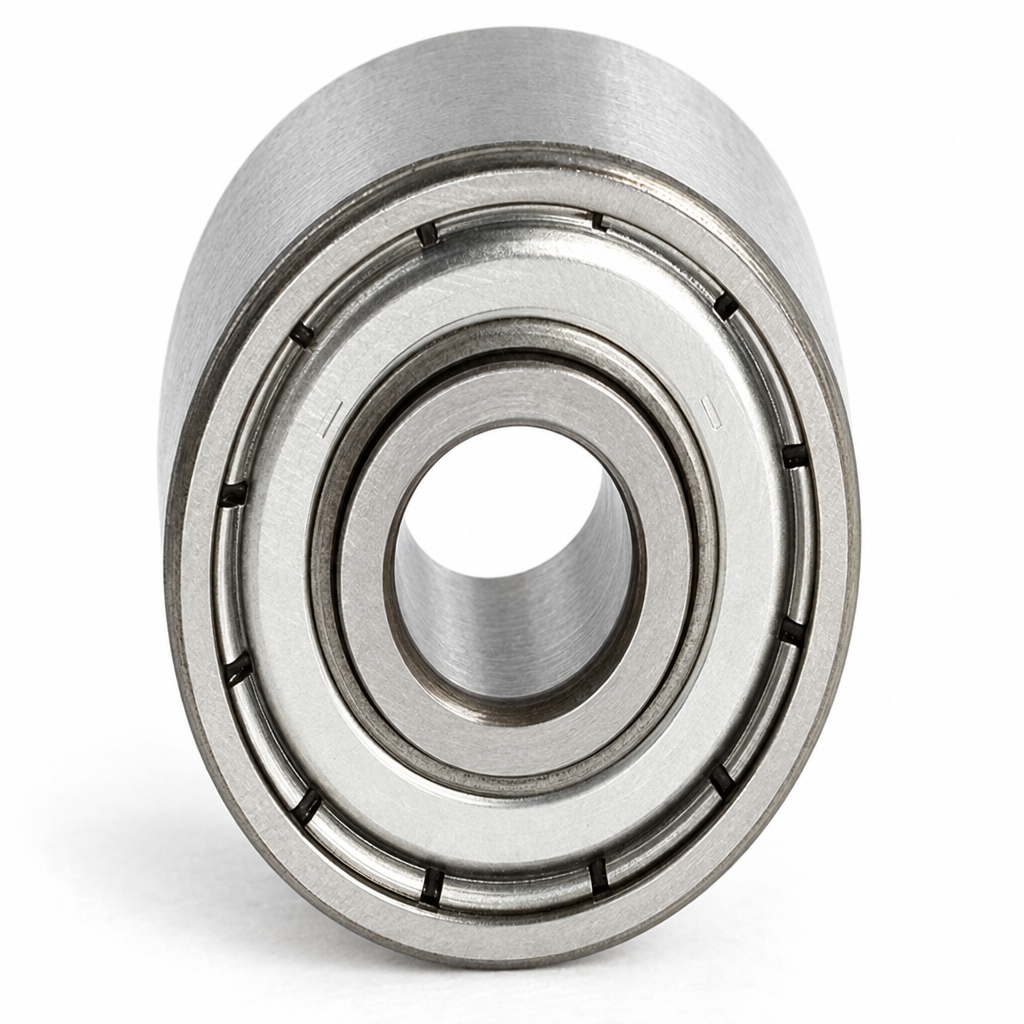

Saved to: /home/abi/vison-model/Vision-Based Product Attribution and BOM Mapping/bearing_enhanced.png


In [15]:
import os
from pathlib import Path
from openai import OpenAI
from IPython.display import display, Image

client = OpenAI()  # Reads OPENAI_API_KEY from the environment

image_path = Path(
    "/home/abi/vison-model/"
    "Vision-Based Product Attribution and BOM Mapping/"
    "data/combined/crops/bearing/CROP-000344.jpg"
)

with open(image_path, "rb") as image_file:
    result = client.images.edit(
        model="gpt-image-2.5-sunburst",
        image=image_file,
        prompt=(
            "Attempt to improve the visibility of this mechanical bearing. "
            "Reduce blur and noise while preserving the original geometry, "
            "dimensions, rings, holes, and visible markings. "
            "Do not invent or add mechanical details. "
            "Keep the background unchanged where possible."
        ),
        size="1024x1024",
        quality="high",
    )

output_path = Path("bearing_enhanced.png")
output_path.write_bytes(
    __import__("base64").b64decode(result.data[0].b64_json)
)

display(Image(filename=str(output_path)))
print("Saved to:", output_path.resolve())